# Homework 5 Python Programming

Last updated: Nov 14, 2025

## Learning Objectives

This assignment focuses on Deep Q-Learning, a fundamental reinforcement learning algorithm. You'll implement a DQN agent to solve the CartPole environment from OpenAI Gym. The CartPole problem involves balancing a pole on a cart by moving the cart left or right.

**What you'll build:**
- A Q-Network (neural network for Q-value approximation)
- DQN Agent (with epsilon-greedy exploration, target network, and learning logic)
- Training Loop (to train the agent over multiple episodes)
- Evaluation and Visualization (to test and observe the trained agent)

## Instructions

Please answer all questions in this notebook. You will see comments like "# YOUR CODE HERE" and "# END YOUR CODE" marking where you need to write code.


## Setup

**IMPORTANT**: Before you edit this notebook, you will need to make your own copy (otherwise your edits **will not be saved**).  You can do so by clicking the "File" dropdown in the upper left, and then selecting "Save a copy in Drive" as shown in the screenshot below.

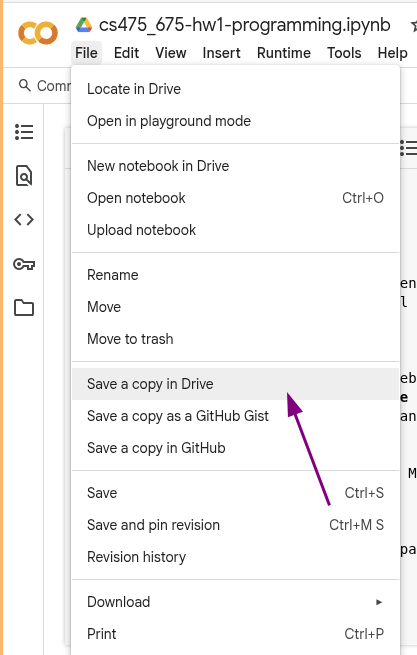

Optional: While you can finish this assignment using CPU only, you may speed up your training by enabling a GPU accelerator. For this assignment, a free-tier T4 GPU should be more than enough for you to use. If you have signed up for Colab Education Free Trial, you would have access to A100 or L4 GPU, either of these would be an overkill.

Below are the steps to enable GPU acceleration.


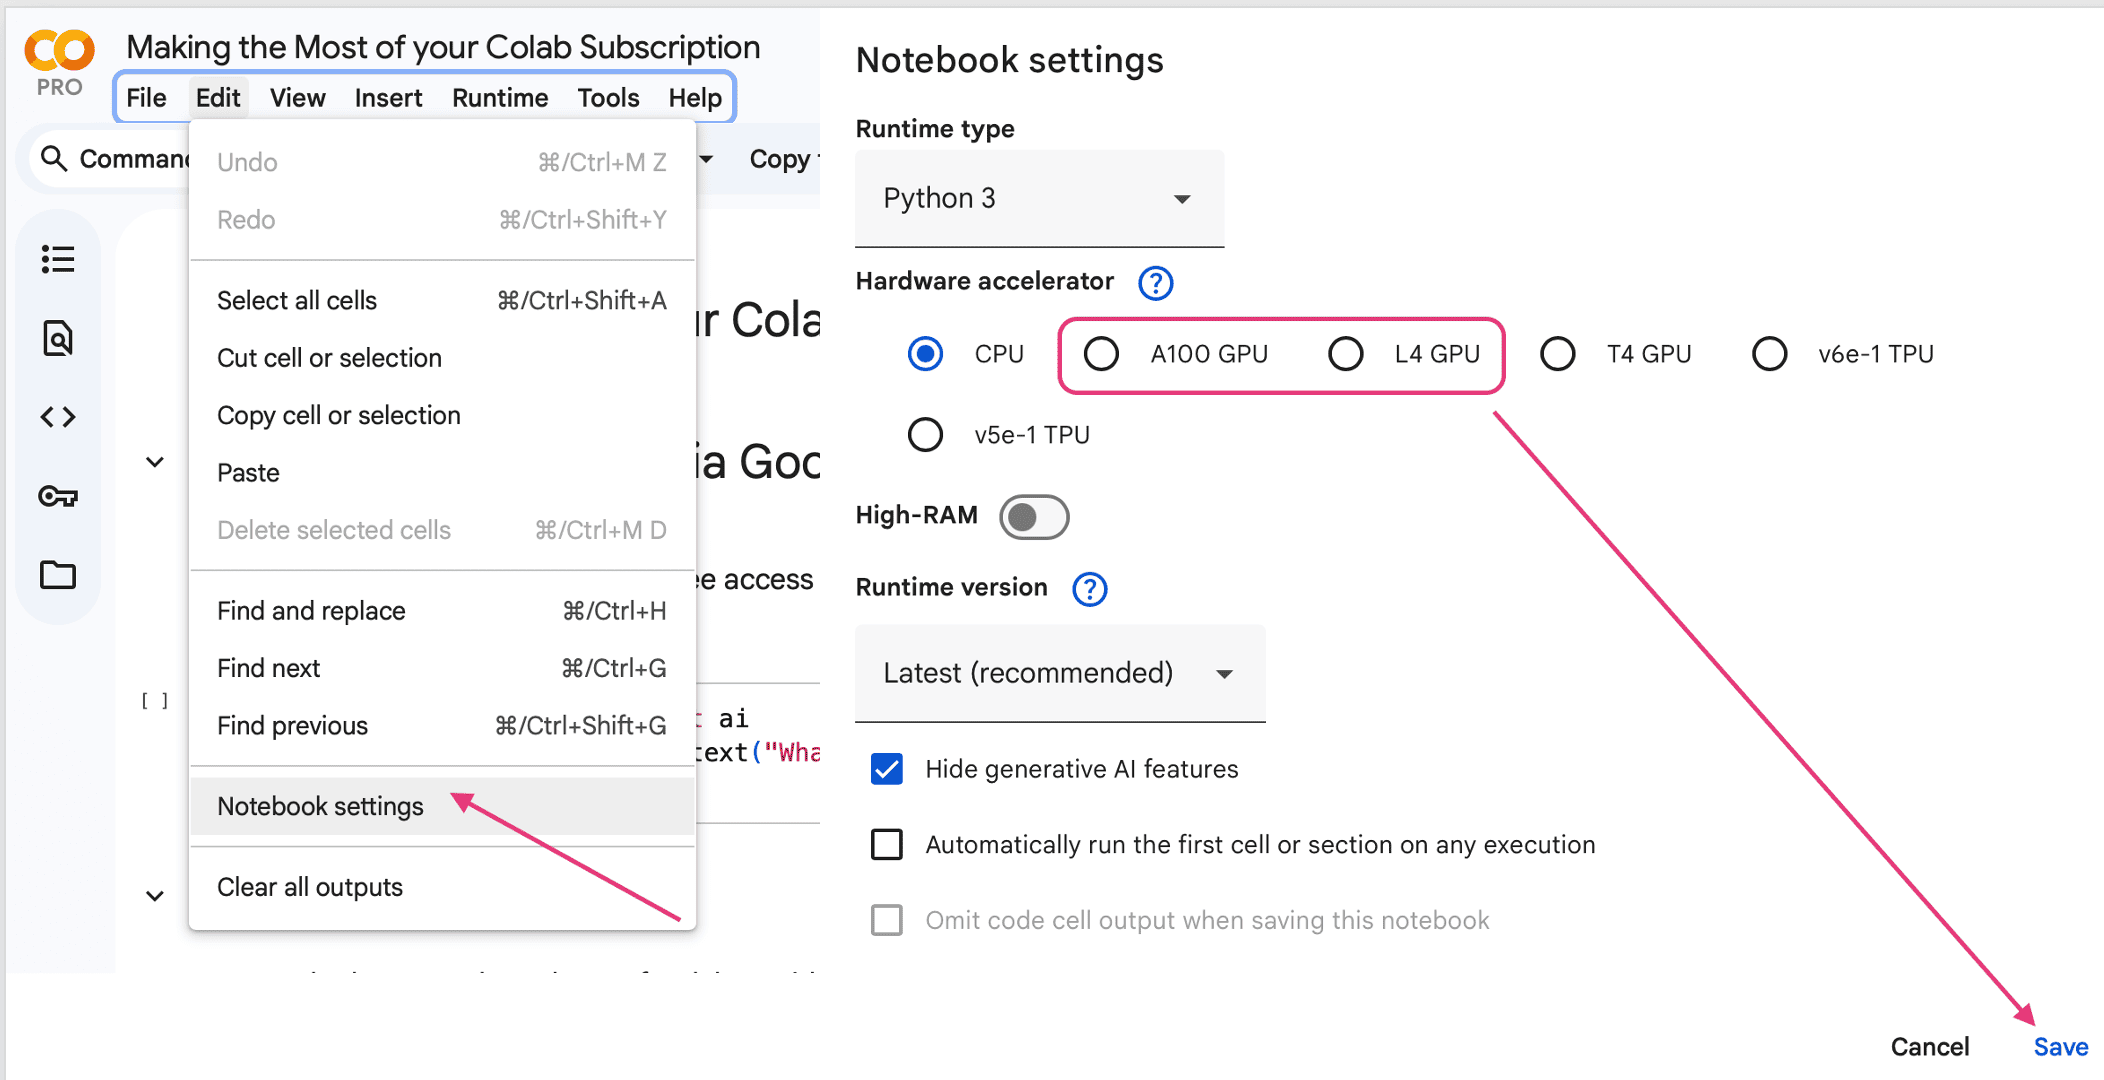

In [6]:
# Install required packages
%pip install -q numpy pandas matplotlib scikit-learn datasets tqdm torch ipywidgets torchvision gymnasium pygame

## Student Information
**IMPORTANT**: Fill in your information in the cell below before starting the assignment.

In [7]:
# IMPORTANT: This cell contains metadata for grading. Do not delete this cell.
# STUDENT INFORMATION - REQUIRED
# Fill in your information below

JHED_ID = "csmit469"  # Your JHED ID (e.g., "zhuang86" - the part before @jhu.edu)
COLAB_LINK = "https://colab.research.google.com/drive/1amocEplEkMUxE9AkWqdgerG2RIsLa4Zo?usp=sharing"  # Public sharing link to this Colab notebook
                  # To get this: "Share" on upper right corner -> "Copy link" (make sure it's set to "Anyone with the link")

# Verify your information is entered
assert JHED_ID != "", "Please enter your JHED ID"
assert COLAB_LINK != "", "Please enter your Colab sharing link"
assert "colab.research.google.com" in COLAB_LINK or COLAB_LINK == "LOCAL", "Please enter a valid Colab link or 'LOCAL' if testing locally"

print(f"JHED ID: {JHED_ID}")
print(f"Colab Link: {COLAB_LINK}")

JHED ID: csmit469
Colab Link: https://colab.research.google.com/drive/1amocEplEkMUxE9AkWqdgerG2RIsLa4Zo?usp=sharing


In [8]:
# Setup and imports
import random
import warnings
from collections import deque
from datetime import datetime
from typing import List

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from IPython.display import HTML, Image, clear_output, display
from matplotlib.animation import FuncAnimation, PillowWriter

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')



## Part 1: RL-DQN

### Introduction to Deep Q-Networks (DQN)

Deep Q-Networks combine Q-learning with deep neural networks to handle high-dimensional state spaces. The key innovations of DQN include:

1. **Experience Replay**: Store past experiences (state, action, reward, next_state) in a replay buffer and sample randomly during training. This breaks the correlation between consecutive samples and improves learning stability.

2. **Target Network**: Use a separate network (updated less frequently) to compute target Q-values. This prevents the "moving target" problem and stabilizes training.

3. **Q-Value Approximation**: Instead of maintaining a Q-table (which is infeasible for large state spaces), use a neural network to approximate Q-values.

### The CartPole Environment

You'll train your agent on the **CartPole-v1** environment:
- **State**: 4 values representing cart position, cart velocity, pole angle, and pole angular velocity
- **Actions**: 2 discrete actions (push cart left or right)
- **Reward**: $+1$ for every timestep the pole remains upright
- **Episode**: Ends when pole angle exceeds $\pm 12$ degrees  or cart moves beyond $\pm 2.4$ units
- **Goal**: Keep the pole balanced for as long as possible (maximum 500 steps)

In the following sections, you will implement each component of the DQN algorithm step by step. We start by specifying the computing device we will use. If you have enabled hardware acceleration with NVIDIA GPUs, `torch.cuda.is_available()` should return `True`. We also need to set a reproducibility seed.

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Set random seeds for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)
    # For deterministic behavior (may impact performance slightly)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

Using device: cpu


### Step 1: Build a Neural Network for Q-value approximation

**Task Overview:** Create a simple neural network that takes a state as input and outputs Q-values for each possible action.

**Network Architecture:**
- Input layer: `state_size` neurons (4 for CartPole: cart position, cart velocity, pole angle, pole angular velocity)
- Hidden layer 1: `hidden_size` neurons (default 128) with ReLU activation
- Hidden layer 2: `hidden_size` neurons (default 128) with ReLU activation
- Output layer: `action_size` neurons (2 for CartPole: left and right)

**What you need to implement:**
- Complete the `forward()` method
- Apply ReLU activation after each hidden layer
- The output layer should NOT have an activation function (raw Q-values)

**Hint:** Use `F.relu()` for ReLU activation and pass the data through each layer (fc1, fc2, fc3) in sequence.

In [10]:
class QNetwork(nn.Module):
    """
    Neural Network for Q-value approximation.
    """
    def __init__(self, state_size: int, action_size: int, hidden_size: int = 128):
        super(QNetwork, self).__init__()
        """
        TODO Task 1: Define the neural network layers.
        """
        # YOUR CODE HERE
        self.fc1 = nn.Linear(state_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, action_size)
        # END YOUR CODE

    def forward(self, x):
        """
        TODO Task 1: Forward pass with ReLU activations
        """
        # YOUR CODE HERE
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        # END YOUR CODE
        return x

A `ReplayBuffer` is provided for you convenience.

In [11]:
class ReplayBuffer:
    """
    Experience replay buffer to store and sample transitions.
    """
    def __init__(self, capacity: int):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        """Store a transition"""
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int) -> List:
        """
        Random sampling from buffer
        """
        return random.sample(self.buffer, batch_size)

    def __len__(self):
        return len(self.buffer)

### Step 2: Deep Q-Network Agent with experience replay and target network

**Task Overview:** Implement the core DQN agent that learns from experience.

The DQN agent consists of several key components:

1. **Two Neural Networks:**
   - **Q-Network (main network)**: Updated every step during training
   - **Target Network**: Copy of Q-Network updated less frequently (every `update_target_every` steps)

2. **Experience Replay Buffer:**
   - Stores past experiences: `(state, action, reward, next_state, done)`
   - During training, we sample random batches from this buffer
   - Breaks correlation between consecutive experiences

3. **Epsilon-Greedy Exploration:**
   - Epsilon ($\epsilon$): Probability of taking a random action
   - Starts high (explore more) and decays over time (exploit more)
   - Balances exploration of new strategies vs. exploitation of learned knowledge

**Your Tasks in this section:**

**Task 2: Implement `replay()` method** - The learning step
- Sample a batch of experiences from the replay buffer
- Compute current Q-values from the main network
- Compute target Q-values using the Bellman equation: `Q_target = reward + gamma * max(Q_next)`
- Calculate loss (Mean Squared Error between current and target Q-values)
- Perform backpropagation and gradient descent

**Task 3: Implement `act()` method** - Epsilon-greedy action selection
- During training: With probability ε, choose random action; otherwise choose best action
- During evaluation: Always choose the action with highest Q-value
- Use `torch.no_grad()` when getting Q-values to avoid unnecessary gradient computation

In [12]:
class DQNAgent:
    """
    Deep Q-Network Agent with experience replay and target network.
    """
    def __init__(
        self,
        state_size: int,
        action_size: int,
        lr: float = 1e-3,
        gamma: float = 0.99,
        epsilon: float = 1.0,
        epsilon_decay: float = 0.995,
        epsilon_min: float = 0.01,
        buffer_size: int = 10000,
        batch_size: int = 32,
        update_target_every: int = 10
    ):
        self.state_size = state_size
        self.action_size = action_size
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.batch_size = batch_size
        self.update_target_every = update_target_every
        self.update_counter = 0

        # Neural networks (using GPU if available)
        self.q_network = QNetwork(state_size, action_size).to(device)
        self.target_network = QNetwork(state_size, action_size).to(device)
        self.update_target_network()

        # Optimizer
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)

        # Replay buffer
        self.memory = ReplayBuffer(buffer_size)

    def update_target_network(self):
        """Copy weights from main network to target network"""
        self.target_network.load_state_dict(self.q_network.state_dict())

    def act(self, state: np.ndarray, training: bool = True) -> int:
        """
        TODO Task 3: Implement epsilon-greedy action selection

        During training:
        - With probability epsilon: choose random action
        - With probability (1-epsilon): choose action with highest Q-value

        During evaluation (training=False):
        - Always choose action with highest Q-value

        Args:
            state: Current state
            training: Whether the agent is training
        Returns:
            Selected action (0 or 1 for CartPole)
        """
        if training and random.random() < self.epsilon:
            # YOUR CODE HERE (1 line)
            return random.randrange(self.action_size)
            # END YOUR CODE
        else:
            # Convert state to tensor and move to device
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)

            # YOUR CODE HERE
            # Get Q-values from network (no gradient needed)
            # Return the action with maximum Q-value
            with torch.no_grad():
                q_values = self.q_network(state_tensor)
            return int(torch.argmax(q_values, dim=1).item())
            # END YOUR CODE

    def remember(self, state, action, reward, next_state, done):
        """Store transition in replay buffer"""
        self.memory.push(state, action, reward, next_state, done)

    def replay(self):
        """
        TODO Task 2: Implement the learning step using experience replay

        This implements the Q-learning update from lecture slide 20:
        Q^(t+1)(s,a) ← (1-α)Q^(t)(s,a) + α[R(s,s') + γ max_a' Q(s',a')]

        In our neural network version:
        - Q^(t)(s,a) is the current Q-value from our network
        - R(s,s') is the immediate reward
        - γ is the discount factor
        - max_a' Q(s',a') is computed using the target network

        Steps:
        1. Return if not enough samples in buffer
        2. Sample a batch from replay buffer
        3. Prepare batch tensors and move to device
        4. Compute current Q-values for taken actions
        5. Compute target Q-values using target network
        6. Compute loss (MSE) and perform backpropagation
        7. Update target network periodically
        8. Decay epsilon
        """
        if len(self.memory) < self.batch_size:
            return

        # Sample batch
        batch = self.memory.sample(self.batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)

        # Convert to tensors and move to GPU if available
        states = torch.FloatTensor(states).to(device)
        actions = torch.LongTensor(actions).to(device)
        rewards = torch.FloatTensor(rewards).to(device)
        next_states = torch.FloatTensor(next_states).to(device)
        dones = torch.FloatTensor(dones).to(device)

        # Step 1: Get current Q-values for the actions taken
        # .gather() is used to gather values along a dimension specified by the index.
        # squeeze(1) is used to remove the dimension of size 1. For example, if a tensor is of shape (10, 1),
        # squeezing it will result in a tensor of shape 10. unsqueeze(1) does the opposite.
        current_q_values = self.q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        # Step 2: Get next Q-values from target network
        with torch.no_grad():
            next_q_values = self.target_network(next_states).max(1)[0]

        # Step 3: Compute target values using Bellman equation
        # target = reward + gamma * max_next_q * (1 - done)
        # Hint: Use q_network(states).gather()
            # YOUR CODE HERE
            target_q_values = target_q_values = rewards + self.gamma * next_q_values * (1 - dones)
            # END YOUR CODE


        # Step 4: Compute loss (MSE between current Q and target)
        loss = F.mse_loss(current_q_values, target_q_values)



        # Step 5: Backpropagation
        # - Zero gradients
        # - Backward pass
        # - Optimizer step

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()


        # Update target network
        self.update_counter += 1
        if self.update_counter % self.update_target_every == 0:
            self.update_target_network()

        # Decay epsilon
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

### Step 3: Implement the main training loop

**Task Overview:** Create the training loop that ties everything together.

The training loop is where the agent interacts with the environment and learns over time. Here's what happens in each episode:

**Episode Structure:**
1. **Reset environment** - Get initial state
2. **Episode loop** - Repeat until episode ends (pole falls or max steps reached):
   - Agent selects an action (using epsilon-greedy strategy)
   - Environment returns: next_state, reward, and done flag
   - Store experience in replay buffer
   - Agent learns from experience (replay)
   - Update state
   - Track cumulative reward (score)
3. **Update target network** - Every `update_target_every` episodes
4. **Decay epsilon** - Gradually reduce exploration rate
5. **Track performance** - Record scores for analysis

**Task 4: Implement `train_agent_notebook()` function**
- Complete the outer loop that iterates through episodes
- Inside each episode, implement the interaction loop
- Update the target network periodically
- Decay epsilon after each episode
- TODO:
   - Select action using `agent.act(state, training=True)`
   - Execute action in environment using `env.step(action)`
   - Store experience using `agent.remember(...)`
   - Trigger learning using `agent.replay()`
   - Update state and accumulate rewards

In [13]:
def train_agent_notebook(episodes=300):
    """
    TODO Task 4: Implement the main training loop

    For each episode:
    1. Reset environment and get initial state
    2. For each step in episode:
       - Select action using agent.act()
       - Take action in environment
       - Store transition in replay buffer
       - Learn from replay buffer
       - Update state
    3. Track and print statistics

    Args:
        episodes: Number of episodes to train
        render_every: Render environment every N episodes (0 to disable)

    Returns:
        agent: Trained agent
        scores: List of episode scores
    """
    env = gym.make('CartPole-v1')
    state_size = env.observation_space.shape[0]
    action_size = env.action_space.n

    agent = DQNAgent(state_size, action_size)
    scores = []
    scores_window = deque(maxlen=100)

    # Progress display
    progress_html = """
    <div id="progress" style="background: #f8f9fa; padding: 10px; border-radius: 5px;">
        <div style="background: #007bff; width: 0%; height: 20px; border-radius: 3px;"></div>
        <div style="text-align: center; margin-top: 5px;">Episode 0/{}</div>
    </div>
    """.format(episodes)
    progress_display = display(HTML(progress_html), display_id=True)

    for episode in range(1, episodes + 1):
        # Reset environment
        state, _ = env.reset()
        score = 0
        done = False

        # TODO Task 5: Complete training loop
        while not done:
            # Remember to:
            # - Track total reward
            # - Call agent.remember() to store transitions
            # - Call agent.replay() to learn
            # - Break when done
            # YOUR CODE HERE
            # Select and perform action
            action = agent.act(state, training=True)
            next_state, reward, done, _, _ = env.step(action)

            # Store transition
            agent.remember(state, action, reward, next_state, done)

            # Learn from experience
            agent.replay()

            # Update state and score
            state = next_state
            score += reward
            # END YOUR CODE

        scores.append(score)
        scores_window.append(score)

        # Update progress bar
        if episode % 5 == 0:
            progress = (episode / episodes) * 100
            avg_score = np.mean(scores_window)
            progress_html = f"""
            <div style="background: #f8f9fa; padding: 10px; border-radius: 5px;">
                <div style="background: {'#28a745' if avg_score >= 195 else '#007bff'};
                           width: {progress}%; height: 20px; border-radius: 3px;"></div>
                <div style="text-align: center; margin-top: 5px;">
                    Episode {episode}/{episodes} | Score: {score:.0f} |
                    Avg: {avg_score:.1f} | ε: {agent.epsilon:.3f}
                </div>
            </div>
            """
            progress_display.update(HTML(progress_html))

        # Check if solved
        if np.mean(scores_window) >= 195.0 and episode >= 100:
            print(f"\nEnvironment solved in {episode} episodes!")
            break

    env.close()
    return agent, scores

### Step 4: Evaluation and Visualization

**Task Overview:** Train your agent and visualize the learning progress.

Now that you've implemented all the core components, it's time to train your agent and see how it learns!

In [21]:
agent, scores = train_agent_notebook(episodes=300)


Environment solved in 100 episodes!


In [22]:
def evaluate_agent_notebook(agent, num_episodes=10):
    """Evaluate trained agent"""
    env = gym.make('CartPole-v1')
    scores = []

    for ep in range(num_episodes):
        state, _ = env.reset()
        score = 0
        done = False

        while not done:
            action = agent.act(state, training=False)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            state = next_state
            score += reward

        scores.append(score)
        print(f"Episode {ep+1}: Score = {score}")

    env.close()
    avg_score = np.mean(scores)

    return avg_score

In [23]:
evaluate_agent_notebook(agent, num_episodes=10)

Episode 1: Score = 337.0
Episode 2: Score = 276.0
Episode 3: Score = 256.0
Episode 4: Score = 440.0
Episode 5: Score = 251.0
Episode 6: Score = 266.0
Episode 7: Score = 244.0
Episode 8: Score = 432.0
Episode 9: Score = 452.0
Episode 10: Score = 298.0


np.float64(325.2)

You can visualize the results using `display_results` with the scores calculated during training.

In [24]:
def display_results(scores):
    """Display comprehensive results in notebook"""
    clear_output(wait=True)

    # Create and display plots
    _, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Episode scores
    axes[0].plot(scores, 'b-', alpha=0.6, linewidth=1)
    axes[0].fill_between(range(len(scores)), scores, alpha=0.3)
    axes[0].set_xlabel('Episode')
    axes[0].set_ylabel('Score')
    axes[0].set_title('Episode Scores')
    axes[0].grid(True, alpha=0.3)

    # Rolling average
    window = 100
    rolling_avg = [np.mean(scores[max(0, i-window+1):i+1]) for i in range(len(scores))]
    axes[1].plot(rolling_avg, 'g-', linewidth=2, label='Rolling Avg')
    axes[1].axhline(y=195, color='r', linestyle='--', linewidth=2, label='Target')
    axes[1].fill_between(range(len(rolling_avg)), rolling_avg, alpha=0.3, color='green')
    axes[1].set_xlabel('Episode')
    axes[1].set_ylabel('Average Score')
    axes[1].set_title('100-Episode Rolling Average')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


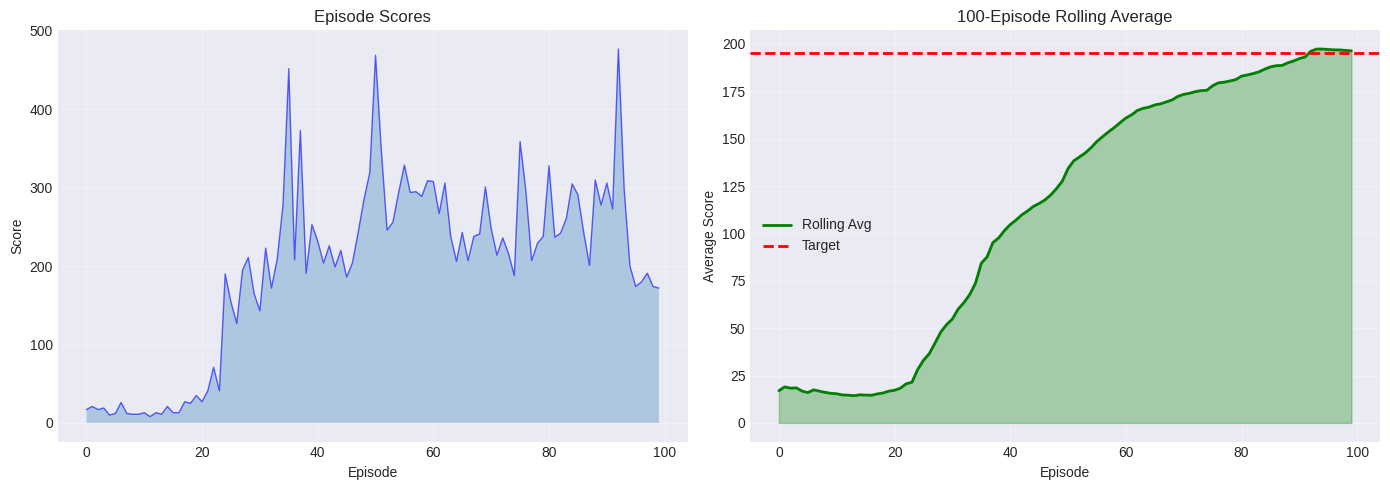

In [25]:
display_results(scores)

## CartPole Visualization

Now let's visualize the trained agent controlling the cart pole! This will create an animated GIF showing the cart pole balancing in action.

**What you'll see:**
- An animated GIF of your trained agent balancing the pole
- The cart moving left and right to keep the pole upright
- If training was successful, the pole should stay balanced for the full 500 steps

**Note:**
- The visualization uses the trained agent in evaluation mode (no exploration)
- Generating the GIF may take a minute - be patient!
- If you see the pole falling quickly, your implementation may need debugging


In [26]:
def visualize_cartpole(agent, num_episodes=3, save_path='cartpole_evaluation.gif'):
    """
    Visualize the cart pole during evaluation and save as an animated GIF.
    Runs and visualizes exactly 3 evaluation episodes.

    Args:
        agent: Trained DQN agent
        num_episodes: Number of episodes to evaluate and visualize (default=3)
        save_path: Path to save the GIF
        jhed_id: JHED ID to display on the GIF
        colab_link: Colab link to display on the GIF
    """
    env = gym.make('CartPole-v1', render_mode='rgb_array')

    # Get timestamp
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    all_frames = []
    episode_scores = []

    # Run exactly num_episodes (default 3) and visualize all of them
    for episode in range(num_episodes):
        state, _ = env.reset()
        score = 0
        done = False
        frames = []

        while not done:
            # Capture frame for every episode
            frame = env.render()
            frames.append(frame)

            # Take action
            action = agent.act(state, training=False)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            state = next_state
            score += reward

        # Store frames and score for this episode
        all_frames.append(frames)
        episode_scores.append(score)

        print(f"Episode {episode+1}: Score = {score}")

    env.close()

    # Create the animated GIF
    print(f"\nCreating visualization GIF...")
    print(f"Visualizing all {num_episodes} evaluation episodes")

    # Note if perfect scores
    if all(score >= 499 for score in episode_scores):
        print("Note: Agent achieved perfect scores! Movement may appear minimal as it's perfectly balancing.")
        print("   The pole is being kept upright with small, precise adjustments.")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.axis('off')

    # Flatten frames from all episodes with episode boundaries marked
    all_frames_flat = []
    for ep_idx, frames in enumerate(all_frames):
        for frame_idx, frame in enumerate(frames):
            all_frames_flat.append((frame, ep_idx, frame_idx, episode_scores[ep_idx]))

    # Create animation - Initialize with first frame
    if all_frames_flat:
        im = ax.imshow(all_frames_flat[0][0])

    # Main info text (episode, frame, score)
    text = ax.text(0.5, 0.95, '', transform=ax.transAxes,
                   ha='center', va='top', fontsize=12,
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # Additional info text (JHED_ID, COLAB_LINK, Timestamp) - positioned at bottom for grading
    info_lines = []
    if JHED_ID:
        info_lines.append(f'JHED ID: {JHED_ID}')
    if COLAB_LINK:
        info_lines.append(f'Colab: {COLAB_LINK}')
    info_lines.append(f'Generated: {timestamp}')

    info_text = ax.text(0.5, 0.02, '\n'.join(info_lines), transform=ax.transAxes,
                        ha='center', va='bottom', fontsize=9,
                        bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))

    def animate(i):
        frame, ep_idx, frame_idx, score = all_frames_flat[i]
        im.set_array(frame)

        text.set_text(f'Episode {ep_idx+1} | Frame {frame_idx+1} | Score: {score:.0f}')
        return [im, text, info_text]

    anim = FuncAnimation(fig, animate, frames=len(all_frames_flat),
                        interval=50, blit=True, repeat=True)

    writer = PillowWriter(fps=20)
    anim.save(save_path, writer=writer)
    plt.close()

    print(f"Visualization saved to '{save_path}'")
    print(f"Average score across {num_episodes} episodes: {np.mean(episode_scores):.1f}")

    # Display the GIF in the notebook
    display(Image(save_path))

    return episode_scores

In [27]:
# Visualize the cart pole in action!
print("Visualizing Cart Pole Performance...")
visualize_cartpole(agent, num_episodes=3)


Output hidden; open in https://colab.research.google.com to view.

You have successfully built and trained a simple reinforcement learning agent using Q-learning to solve the CartPole environment.

You are now ready to submit your work! Please follow the submission instructions below carefully. Note that the autograder may take some time to run (typically 10-40 minutes depending on server load), so please be patient after submitting.

On a separate note, if you find reinforcement learning interesting, the CS department offers a course on it: 601.479/679 ML: Reinforcement Learning. ECE also offers a graduate-level RL course: 520.637 Foundations of Reinforcement Learning.

If you are specifically interested in the topics, discussions, and challenges of RL in large language/vision models, you might be interested in, but not limited to, these courses: CS 601.471/671 NLP: Self-supervised Models, CS 601.771 Advances in Self-supervised Models, CS 601.773: Machine Social Intelligence.  

And that wraps up our programming assignments for this semester. Good luck on your final exams!

## Submission

**IMPORTANT SUBMISSION INSTRUCTIONS:**
1. Make sure all cells are executed (Run All): This makes sure that your notebook does not produce errors. We will use the results produced by Gradescope autograder for grading.
2. Download this notebook: File -> Download -> Download .ipynb
3. Submit the .ipynb file to Gradescope
4. Do NOT rename the file when downloading
5. If your browser adds numbers like (1) or (2) to the filename, that's OK - the autograder will handle it